In [22]:
!nvidia-smi
from google.colab import drive
drive.mount('/content/drive')

Thu Oct 15 16:00:21 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   47C    P0             27W /   70W |     107MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [23]:
import os, random, time, copy, shutil
import numpy as np, pandas as pd
import torch, torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torch.optim.lr_scheduler import CosineAnnealingLR
from torchvision import transforms, models
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, roc_curve, confusion_matrix
import matplotlib.pyplot as plt
ROOT   = '/content/drive/MyDrive/glaucoma_G1020'
RAW_G  = f'{ROOT}/raw/G1020'                  # contains G1020.csv and the Images folder
OUT    = f'{ROOT}/results_g1020_sanity'       # every result of this sanity check goes here
LOCAL  = '/content/G1020_local'               # fast local copy of the images
PRED_DIR = f'{OUT}/predictions'
for d_ in (OUT, PRED_DIR, LOCAL): os.makedirs(d_, exist_ok=True)
IMG, BATCH, EPOCHS, LR = 224, 32, 15, 1e-4
SEEDS  = [42, 7, 123]
MODELS = ['resnet50', 'densenet121', 'mobilenet_v2', 'efficientnet_b0', 'inception_v3']
LABEL  = {'resnet50': 'ResNet50', 'densenet121': 'DenseNet121', 'mobilenet_v2': 'MobileNetV2',
          'efficientnet_b0': 'EfficientNet-B0', 'inception_v3': 'InceptionV3'}
IMG_EXT = ('.jpg', '.jpeg', '.png', '.tif', '.tiff', '.bmp')
DEVICE  = 'cuda' if torch.cuda.is_available() else 'cpu'
USE_AMP = (DEVICE == 'cuda')
print('Using device:', DEVICE)
def seed_everything(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

Using device: cuda


In [24]:
lab = pd.read_csv(f'{RAW_G}/G1020.csv')
print('Columns:', lab.columns.tolist())
print(lab.head(), '\n rows in CSV:', len(lab))
ID_COL, LABEL_COL = 'imageID', 'binaryLabels'      # edit if your CSV uses other names
assert ID_COL in lab.columns and LABEL_COL in lab.columns, 'edit ID_COL / LABEL_COL above'
print('label values:', sorted(lab[LABEL_COL].unique().tolist()))
print('patient-like columns:', [c for c in lab.columns if 'patient' in c.lower()])
IMG_DIR = f'{RAW_G}/Images'
files = {f.lower(): f for f in os.listdir(IMG_DIR) if f.lower().endswith(IMG_EXT)}
stems = {os.path.splitext(k)[0]: v for k, v in files.items()}
print('image files found:', len(files))
rows, missing = [], []
for _, r in lab.iterrows():
    key = str(r[ID_COL]).strip().lower()
    f = files.get(key) or stems.get(os.path.splitext(key)[0])
    if f is None:
        missing.append(key); continue
    dst = f'{LOCAL}/{f}'
    if not os.path.exists(dst): shutil.copy(f'{IMG_DIR}/{f}', dst)
    rows.append(dict(path=dst, label=int(r[LABEL_COL]), name=f))
df = pd.DataFrame(rows)
df.to_csv(f'{OUT}/g1020_master.csv', index=False)
print('matched images:', len(df), '| CSV rows without image:', len(missing))
print('glaucoma:', int((df.label == 1).sum()), '| normal:', int((df.label == 0).sum()))
assert len(missing) == 0, f'{len(missing)} CSV rows have no image, e.g. {missing[:3]}'
assert set(df.label.unique()) == {0, 1}, 'labels must be 0/1 (check LABEL_COL)'
assert df.name.is_unique, 'duplicate image names'

Columns: ['imageID', 'binaryLabels']
       imageID  binaryLabels
0  image_0.jpg             0
1  image_1.jpg             0
2  image_3.jpg             0
3  image_4.jpg             0
4  image_5.jpg             0 
 rows in CSV: 1020
label values: [0, 1]
patient-like columns: []
image files found: 1020
matched images: 1020 | CSV rows without image: 0
glaucoma: 296 | normal: 724


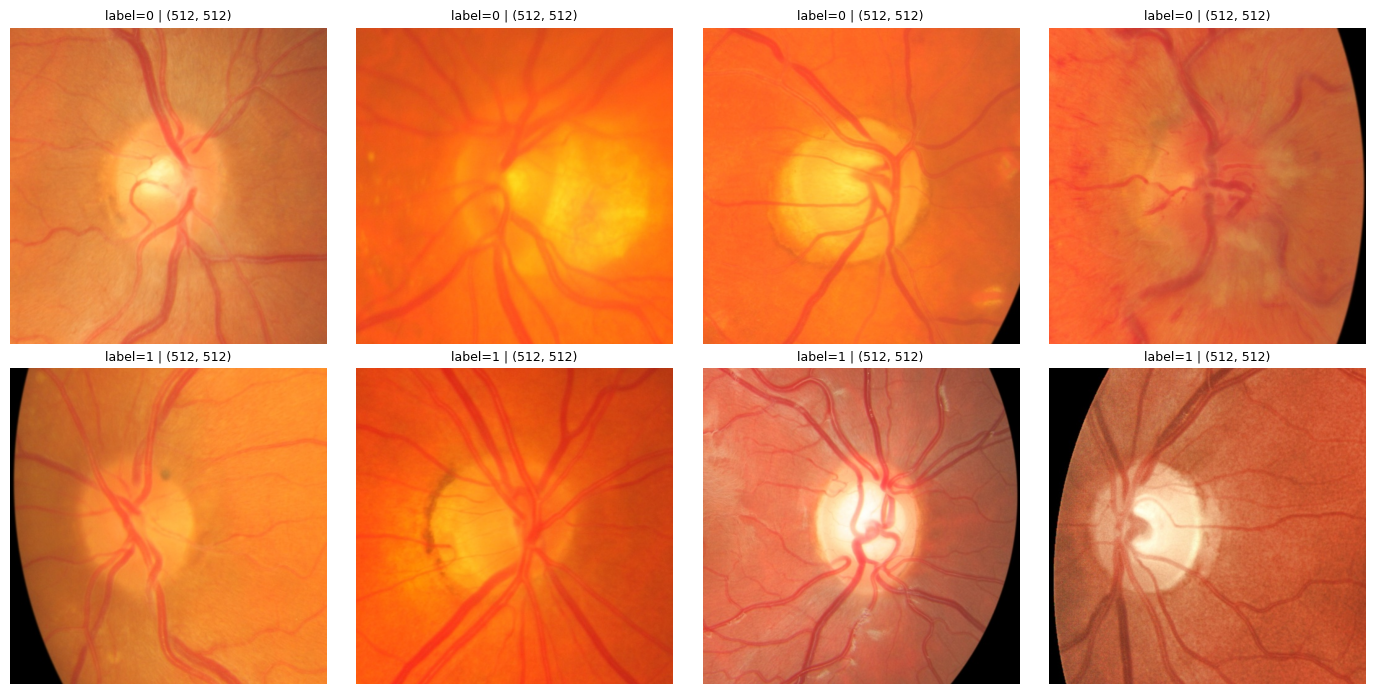

In [25]:
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for row_i, lab_v in enumerate([0, 1]):
    smp = df[df.label == lab_v].sample(4, random_state=0)
    for j, (_, r) in enumerate(smp.iterrows()):
        im = Image.open(r.path)
        axes[row_i, j].imshow(im); axes[row_i, j].axis('off')
        axes[row_i, j].set_title(f'label={r.label} | {im.size}', fontsize=9)
plt.tight_layout(); plt.savefig(f'{OUT}/g1020_sample_images.png', dpi=120); plt.show()


In [26]:
norm = transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
train_tf = transforms.Compose([
    transforms.Resize((IMG, IMG)), transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15), transforms.ColorJitter(0.2, 0.2),
    transforms.ToTensor(), norm])
eval_tf = transforms.Compose([transforms.Resize((IMG, IMG)), transforms.ToTensor(), norm])
class FundusDS(Dataset):
    def __init__(self, frame, tf):
        self.paths = frame.path.tolist()
        self.labels = frame.label.values.astype('float32')
        self.tf = tf
    def __len__(self): return len(self.paths)
    def __getitem__(self, i):
        img = Image.open(self.paths[i]).convert('RGB')
        return self.tf(img), torch.tensor(self.labels[i])
def split_source(d, seed):
    trval, te = train_test_split(d, test_size=0.15, stratify=d.label, random_state=seed)
    tr, va = train_test_split(trval, test_size=0.15 / 0.85, stratify=trval.label, random_state=seed)
    return tr, va, te
for s in SEEDS:
    tr, va, te = split_source(df, s)
    print(f'seed {s:3d}: train {len(tr)} | val {len(va)} | test {len(te)} '
          f'(test glaucoma {int(te.label.sum())}) | glaucoma ratio '
          f'{tr.label.mean():.2f} / {va.label.mean():.2f} / {te.label.mean():.2f}')

seed  42: train 714 | val 153 | test 153 (test glaucoma 44) | glaucoma ratio 0.29 / 0.29 / 0.29
seed   7: train 714 | val 153 | test 153 (test glaucoma 44) | glaucoma ratio 0.29 / 0.29 / 0.29
seed 123: train 714 | val 153 | test 153 (test glaucoma 44) | glaucoma ratio 0.29 / 0.29 / 0.29


In [27]:
def make_model(name):
    if name == 'resnet50':
        m = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V2)
        m.fc = nn.Linear(m.fc.in_features, 1)
    elif name == 'densenet121':
        m = models.densenet121(weights=models.DenseNet121_Weights.IMAGENET1K_V1)
        m.classifier = nn.Linear(m.classifier.in_features, 1)
    elif name == 'mobilenet_v2':
        m = models.mobilenet_v2(weights=models.MobileNet_V2_Weights.IMAGENET1K_V1)
        m.classifier[1] = nn.Linear(m.classifier[1].in_features, 1)
    elif name == 'efficientnet_b0':
        m = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.IMAGENET1K_V1)
        m.classifier[1] = nn.Linear(m.classifier[1].in_features, 1)
    elif name == 'inception_v3':
        m = models.inception_v3(weights=models.Inception_V3_Weights.IMAGENET1K_V1)
        m.aux_logits = False; m.AuxLogits = None
        m.fc = nn.Linear(m.fc.in_features, 1)
    else:
        raise ValueError(name)
        return m.to(DEVICE)
def predict(model, loader):
    model.eval(); ys, ps = [], []
    with torch.no_grad():
        for x, y in loader:
            x = x.to(DEVICE)
            with torch.autocast(device_type='cuda', dtype=torch.float16, enabled=USE_AMP):
                out = model(x)
            ps.append(torch.sigmoid(out.float()).squeeze(1).cpu().numpy())
            ys.append(y.numpy())
    return np.concatenate(ys), np.concatenate(ps)
def metrics(y, p, thr):
    pred = (p >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    return dict(auc=roc_auc_score(y, p), sens=tp / max(tp + fn, 1),
                spec=tn / max(tn + fp, 1), acc=(tp + tn) / len(y))
def make_loader(frame, tf, shuffle=False, drop_last=False):
    return DataLoader(FundusDS(frame, tf), batch_size=BATCH, shuffle=shuffle,
                      num_workers=2, drop_last=drop_last)
def train_model(name, tr, va, seed, epochs=EPOCHS, patience=5):
    seed_everything(seed)
    model = make_model(name)
    tl = make_loader(tr, train_tf, shuffle=True, drop_last=True)
    vl = make_loader(va, eval_tf)
    pos = float(tr.label.sum()); neg = len(tr) - pos
    crit = nn.BCEWithLogitsLoss(pos_weight=torch.tensor([neg / pos], device=DEVICE))
    opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-4)
    sched = CosineAnnealingLR(opt, T_max=epochs)
    scaler = torch.amp.GradScaler('cuda', enabled=USE_AMP)
    best_auc, best_state, bad = -1.0, None, 0
    for ep in range(epochs):
        model.train(); tot = 0.0
        for x, y in tl:
            x, y = x.to(DEVICE), y.to(DEVICE)
            opt.zero_grad()
            with torch.autocast(device_type='cuda', dtype=torch.float16, enabled=USE_AMP):
                out = model(x).squeeze(1)
            loss = crit(out.float(), y)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            tot += loss.item() * len(x)
        sched.step()
        yv, pv = predict(model, vl)
        auc = roc_auc_score(yv, pv)
        print(f'  [{name}] epoch {ep+1:02d} train_loss {tot/len(tr):.3f} val_auc {auc:.3f}')
        if auc > best_auc:
            best_auc, best_state, bad = auc, copy.deepcopy(model.state_dict()), 0
        else:
            bad += 1
            if bad >= patience: break
    model.load_state_dict(best_state)
    yv, pv = predict(model, vl)
    fpr, tpr, th = roc_curve(yv, pv)
    thr = float(th[np.argmax(tpr - fpr)])
    return model, thr, float(best_auc)

In [33]:
tr, va, te = split_source(df, 42)
model, thr, val_auc = train_model('mobilenet_v2', tr, va, 42)
y, p = predict(model, make_loader(te, eval_tf))
print('threshold', round(thr, 3), '| val AUC', round(val_auc, 3), '| test:',
      {k: round(float(v), 3) for k, v in metrics(y, p, thr).items()})
del model; torch.cuda.empty_cache()

  [mobilenet_v2] epoch 01 train_loss 0.995 val_auc 0.528
  [mobilenet_v2] epoch 02 train_loss 0.955 val_auc 0.563
  [mobilenet_v2] epoch 03 train_loss 0.909 val_auc 0.500
  [mobilenet_v2] epoch 04 train_loss 0.886 val_auc 0.530
  [mobilenet_v2] epoch 05 train_loss 0.832 val_auc 0.542
  [mobilenet_v2] epoch 06 train_loss 0.770 val_auc 0.526
  [mobilenet_v2] epoch 07 train_loss 0.693 val_auc 0.541
threshold 0.454 | val AUC 0.563 | test: {'auc': 0.617, 'sens': 0.409, 'spec': 0.688, 'acc': 0.608}


In [31]:

def make_model(name):
    if name == 'resnet50':
        m = models.resnet50(
            weights=models.ResNet50_Weights.IMAGENET1K_V2
        )
        m.fc = nn.Linear(m.fc.in_features, 1)

    elif name == 'densenet121':
        m = models.densenet121(
            weights=models.DenseNet121_Weights.IMAGENET1K_V1
        )
        m.classifier = nn.Linear(m.classifier.in_features, 1)

    elif name == 'mobilenet_v2':
        m = models.mobilenet_v2(
            weights=models.MobileNet_V2_Weights.IMAGENET1K_V1
        )
        m.classifier[1] = nn.Linear(
            m.classifier[1].in_features, 1
        )

    elif name == 'efficientnet_b0':
        m = models.efficientnet_b0(
            weights=models.EfficientNet_B0_Weights.IMAGENET1K_V1
        )
        m.classifier[1] = nn.Linear(
            m.classifier[1].in_features, 1
        )

    elif name == 'inception_v3':
        m = models.inception_v3(
            weights=models.Inception_V3_Weights.IMAGENET1K_V1
        )
        m.aux_logits = False
        m.AuxLogits = None
        m.fc = nn.Linear(m.fc.in_features, 1)

    else:
        raise ValueError(f"Unknown model name: {name}")

    return m.to(DEVICE)


In [32]:
test_model = make_model('mobilenet_v2')
print(type(test_model))
print(test_model is None)

<class 'torchvision.models.mobilenetv2.MobileNetV2'>
False


In [34]:
RES = f'{OUT}/g1020_sanity_results.csv'
results = pd.read_csv(RES).to_dict('records') if os.path.exists(RES) else []
done = {(int(r['seed']), r['model']) for r in results}
for seed in SEEDS:
    tr, va, te = split_source(df, seed)
    for name in MODELS:
        if (seed, name) in done: continue
        t0 = time.time()
        print(f'=== seed {seed} | {name} (train={len(tr)}, val={len(va)}, test={len(te)}) ===')
        model, thr, val_auc = train_model(name, tr, va, seed)
        y, p = predict(model, make_loader(te, eval_tf))      # test set used ONCE
        m = metrics(y, p, thr)
        results.append(dict(seed=seed, model=name, n_train=len(tr), n_val=len(va),
                            n_test=len(te), n_test_glaucoma=int(te.label.sum()),
                            val_auc=val_auc, thr=thr, **m))
        pd.DataFrame({'name': te.name.values, 'label': y, 'prob': p}).to_csv(
            f'{PRED_DIR}/pred_{name}_seed{seed}.csv', index=False)
        pd.DataFrame(results).to_csv(RES, index=False)         # save after every run
        print(f'  -> TEST AUC {m["auc"]:.3f} sens {m["sens"]:.2f} spec {m["spec"]:.2f} '
              f'acc {m["acc"]:.2f} | {(time.time()-t0)/60:.1f} min\n')
        del model; torch.cuda.empty_cache()
print('finished runs:', len(results), 'of', len(SEEDS) * len(MODELS))

=== seed 42 | resnet50 (train=714, val=153, test=153) ===
Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 186MB/s]


  [resnet50] epoch 01 train_loss 0.975 val_auc 0.528
  [resnet50] epoch 02 train_loss 0.951 val_auc 0.526
  [resnet50] epoch 03 train_loss 0.928 val_auc 0.532
  [resnet50] epoch 04 train_loss 0.894 val_auc 0.522
  [resnet50] epoch 05 train_loss 0.845 val_auc 0.506
  [resnet50] epoch 06 train_loss 0.806 val_auc 0.512
  [resnet50] epoch 07 train_loss 0.705 val_auc 0.497
  [resnet50] epoch 08 train_loss 0.596 val_auc 0.474
  -> TEST AUC 0.587 sens 0.45 spec 0.69 acc 0.62 | 0.8 min

=== seed 42 | densenet121 (train=714, val=153, test=153) ===
Downloading: "https://download.pytorch.org/models/densenet121-a639ec97.pth" to /root/.cache/torch/hub/checkpoints/densenet121-a639ec97.pth


100%|██████████| 30.8M/30.8M [00:00<00:00, 104MB/s]


  [densenet121] epoch 01 train_loss 1.010 val_auc 0.457
  [densenet121] epoch 02 train_loss 0.930 val_auc 0.542
  [densenet121] epoch 03 train_loss 0.873 val_auc 0.558
  [densenet121] epoch 04 train_loss 0.817 val_auc 0.494
  [densenet121] epoch 05 train_loss 0.736 val_auc 0.497
  [densenet121] epoch 06 train_loss 0.642 val_auc 0.540
  [densenet121] epoch 07 train_loss 0.517 val_auc 0.539
  [densenet121] epoch 08 train_loss 0.439 val_auc 0.543
  -> TEST AUC 0.531 sens 0.80 spec 0.24 acc 0.40 | 0.9 min

=== seed 42 | mobilenet_v2 (train=714, val=153, test=153) ===
  [mobilenet_v2] epoch 01 train_loss 0.995 val_auc 0.528
  [mobilenet_v2] epoch 02 train_loss 0.955 val_auc 0.563
  [mobilenet_v2] epoch 03 train_loss 0.909 val_auc 0.500
  [mobilenet_v2] epoch 04 train_loss 0.886 val_auc 0.530
  [mobilenet_v2] epoch 05 train_loss 0.832 val_auc 0.542
  [mobilenet_v2] epoch 06 train_loss 0.770 val_auc 0.526
  [mobilenet_v2] epoch 07 train_loss 0.693 val_auc 0.541
  -> TEST AUC 0.617 sens 0.41 s

100%|██████████| 20.5M/20.5M [00:00<00:00, 148MB/s]


  [efficientnet_b0] epoch 01 train_loss 0.978 val_auc 0.568
  [efficientnet_b0] epoch 02 train_loss 0.954 val_auc 0.535
  [efficientnet_b0] epoch 03 train_loss 0.932 val_auc 0.530
  [efficientnet_b0] epoch 04 train_loss 0.905 val_auc 0.524
  [efficientnet_b0] epoch 05 train_loss 0.889 val_auc 0.518
  [efficientnet_b0] epoch 06 train_loss 0.862 val_auc 0.486
  -> TEST AUC 0.576 sens 0.93 spec 0.14 acc 0.37 | 0.6 min

=== seed 42 | inception_v3 (train=714, val=153, test=153) ===
Downloading: "https://download.pytorch.org/models/inception_v3_google-0cc3c7bd.pth" to /root/.cache/torch/hub/checkpoints/inception_v3_google-0cc3c7bd.pth


100%|██████████| 104M/104M [00:00<00:00, 140MB/s] 


  [inception_v3] epoch 01 train_loss 1.013 val_auc 0.459
  [inception_v3] epoch 02 train_loss 0.949 val_auc 0.470
  [inception_v3] epoch 03 train_loss 0.941 val_auc 0.463
  [inception_v3] epoch 04 train_loss 0.875 val_auc 0.423
  [inception_v3] epoch 05 train_loss 0.792 val_auc 0.495
  [inception_v3] epoch 06 train_loss 0.676 val_auc 0.526
  [inception_v3] epoch 07 train_loss 0.617 val_auc 0.508
  [inception_v3] epoch 08 train_loss 0.525 val_auc 0.513
  [inception_v3] epoch 09 train_loss 0.453 val_auc 0.478
  [inception_v3] epoch 10 train_loss 0.359 val_auc 0.479
  [inception_v3] epoch 11 train_loss 0.321 val_auc 0.471
  -> TEST AUC 0.555 sens 0.20 spec 0.77 acc 0.61 | 1.1 min

=== seed 7 | resnet50 (train=714, val=153, test=153) ===
  [resnet50] epoch 01 train_loss 0.973 val_auc 0.501
  [resnet50] epoch 02 train_loss 0.945 val_auc 0.594
  [resnet50] epoch 03 train_loss 0.934 val_auc 0.556
  [resnet50] epoch 04 train_loss 0.891 val_auc 0.517
  [resnet50] epoch 05 train_loss 0.829 val_a

In [35]:
RES = f'{OUT}/g1020_sanity_results.csv'
res = pd.read_csv(RES)
assert len(res) == len(SEEDS) * len(MODELS), f'expected 15 rows, found {len(res)}: finish Step 8'
assert not res.duplicated(['seed', 'model']).any(), 'duplicate (seed, model) rows'
for m in MODELS:
    assert sorted(res[res.model == m].seed.tolist()) == sorted(SEEDS), f'{m}: seeds missing'
def pm(m, s, d=3): return f'{m:.{d}f} ± {s:.{d}f}'
rank = {m: i for i, m in enumerate(MODELS)}
# ---- Table A: mean ± SD (sample SD, ddof=1) over seeds 42, 7, 123
rows, num = [], []
for m in MODELS:
    r = res[res.model == m]
    rows.append({'Model': LABEL[m],
                 'Val AUC': pm(r.val_auc.mean(), r.val_auc.std(ddof=1)),
                 'Test AUC': pm(r.auc.mean(), r.auc.std(ddof=1)),
                 'Sensitivity': pm(r.sens.mean(), r.sens.std(ddof=1)),
                 'Specificity': pm(r.spec.mean(), r.spec.std(ddof=1)),
                 'Accuracy': pm(r.acc.mean(), r.acc.std(ddof=1))})
    num.append({'model': m, **{f'{c}_mean': r[c].mean() for c in ['val_auc', 'auc', 'sens', 'spec', 'acc']},
                **{f'{c}_sd': r[c].std(ddof=1) for c in ['val_auc', 'auc', 'sens', 'spec', 'acc']}})
tabA = pd.DataFrame(rows)
# ---- Table B: test AUC per seed
tabB = res.pivot(index='model', columns='seed', values='auc').reindex(MODELS)[SEEDS].round(3)
tabB.columns = [f'Seed {s}' for s in SEEDS]
tabB.insert(0, 'Model', [LABEL[m] for m in tabB.index]); tabB = tabB.reset_index(drop=True)
# ---- Table C: all 15 runs
tabC = res.assign(o=res.model.map(rank)).sort_values(['o', 'seed']).drop(columns='o')
tabC = tabC.assign(Model=tabC.model.map(LABEL))[['Model', 'seed', 'n_test', 'n_test_glaucoma',
        'val_auc', 'thr', 'auc', 'sens', 'spec', 'acc']].round(3).reset_index(drop=True)
tabC.columns = ['Model', 'Seed', 'Test n', 'Test glauc.', 'Val AUC', 'Threshold',
                'Test AUC', 'Sens', 'Spec', 'Acc']
for nm, t in [('A_mean_sd', tabA), ('B_auc_per_seed', tabB), ('C_all_runs', tabC)]:
    t.to_csv(f'{OUT}/g1020_table_{nm}.csv', index=False, encoding='utf-8-sig')
pd.DataFrame(num).to_csv(f'{OUT}/g1020_summary_numeric.csv', index=False)
print('TABLE A - G1020 in-domain sanity check, mean ± SD over 3 seeds'); print(tabA.to_string(index=False))
print('\nTABLE B - test AUC per seed'); print(tabB.to_string(index=False))
print('\nTABLE C - all 15 runs'); print(tabC.to_string(index=False))
# ---- automatic sanity flags
flags = []
for _, r in res.iterrows():
    f = []
    if r.auc < 0.70: f.append('test AUC < 0.70')
    if r.sens == 0 or r.spec == 0: f.append('sensitivity or specificity = 0')
    if r.val_auc - r.auc > 0.10: f.append('validation-test AUC gap > 0.10')
    if f: flags.append(f'{LABEL[r.model]} seed {int(r.seed)}: ' + ', '.join(f))
sd_big = [LABEL[m] for m in MODELS if res[res.model == m].auc.std(ddof=1) > 0.05]
if sd_big: flags.append('AUC SD over seeds > 0.05 for: ' + ', '.join(sd_big))
print('\nSANITY FLAGS:', 'none - pipeline looks healthy' if not flags else '')
for f in flags: print(' -', f)

TABLE A - G1020 in-domain sanity check, mean ± SD over 3 seeds
          Model       Val AUC      Test AUC   Sensitivity   Specificity      Accuracy
       ResNet50 0.571 ± 0.034 0.511 ± 0.066 0.386 ± 0.138 0.651 ± 0.106 0.575 ± 0.053
    DenseNet121 0.603 ± 0.040 0.490 ± 0.036 0.432 ± 0.364 0.547 ± 0.295 0.514 ± 0.106
    MobileNetV2 0.575 ± 0.047 0.529 ± 0.092 0.303 ± 0.129 0.722 ± 0.190 0.601 ± 0.108
EfficientNet-B0 0.554 ± 0.051 0.523 ± 0.068 0.750 ± 0.295 0.275 ± 0.313 0.412 ± 0.140
    InceptionV3 0.605 ± 0.069 0.563 ± 0.029 0.492 ± 0.265 0.554 ± 0.241 0.536 ± 0.103

TABLE B - test AUC per seed
          Model  Seed 42  Seed 7  Seed 123
       ResNet50    0.587   0.473     0.473
    DenseNet121    0.531   0.467     0.471
    MobileNetV2    0.617   0.433     0.536
EfficientNet-B0    0.576   0.546     0.446
    InceptionV3    0.555   0.539     0.596

TABLE C - all 15 runs
          Model  Seed  Test n  Test glauc.  Val AUC  Threshold  Test AUC  Sens  Spec   Acc
       ResNet50     

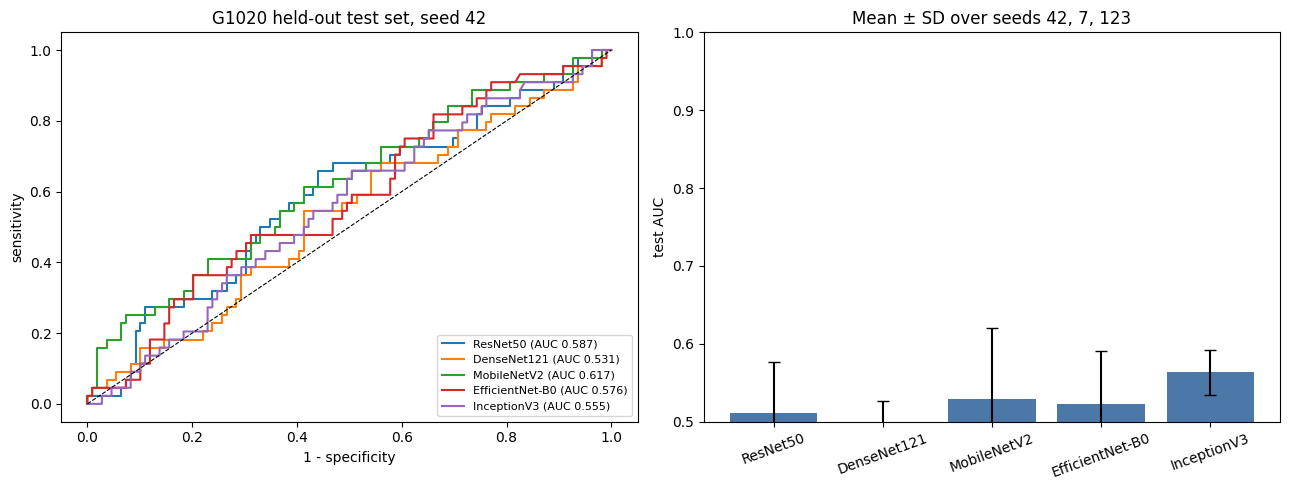

In [36]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for m in MODELS:
    pr = pd.read_csv(f'{PRED_DIR}/pred_{m}_seed42.csv')
    fpr, tpr, _ = roc_curve(pr.label, pr.prob)
    axes[0].plot(fpr, tpr, label=f'{LABEL[m]} (AUC {roc_auc_score(pr.label, pr.prob):.3f})')
axes[0].plot([0, 1], [0, 1], 'k--', lw=0.8)
axes[0].set_xlabel('1 - specificity'); axes[0].set_ylabel('sensitivity')
axes[0].set_title('G1020 held-out test set, seed 42'); axes[0].legend(loc='lower right', fontsize=8)
mu = [res[res.model == m].auc.mean() for m in MODELS]
sd = [res[res.model == m].auc.std(ddof=1) for m in MODELS]
axes[1].bar(range(len(MODELS)), mu, yerr=sd, capsize=4, color='#4C78A8')
axes[1].set_xticks(range(len(MODELS))); axes[1].set_xticklabels([LABEL[m] for m in MODELS], rotation=20)
axes[1].set_ylim(0.5, 1.0); axes[1].set_ylabel('test AUC')
axes[1].set_title('Mean ± SD over seeds 42, 7, 123')
plt.tight_layout(); plt.savefig(f'{OUT}/g1020_sanity_figures.png', dpi=200); plt.show()

In [37]:
!pip install -q reportlab
from reportlab.lib.pagesizes import A4, landscape
from reportlab.lib import colors
from reportlab.lib.styles import getSampleStyleSheet
from reportlab.platypus import (SimpleDocTemplate, Paragraph, Spacer, Table, TableStyle,
                                Image as RLImage, PageBreak)
def make_table(frame):
    data = [list(frame.columns)] + frame.astype(str).values.tolist()
    t = Table(data, repeatRows=1)
    t.setStyle(TableStyle([
        ('BACKGROUND', (0, 0), (-1, 0), colors.HexColor('#1F3864')),
        ('TEXTCOLOR', (0, 0), (-1, 0), colors.white),
        ('FONTNAME', (0, 0), (-1, 0), 'Helvetica-Bold'), ('FONTSIZE', (0, 0), (-1, -1), 8.5),
        ('ROWBACKGROUNDS', (0, 1), (-1, -1), [colors.white, colors.HexColor('#EEF2F8')]),
        ('GRID', (0, 0), (-1, -1), 0.4, colors.grey), ('ALIGN', (1, 0), (-1, -1), 'CENTER'),
        ('TOPPADDING', (0, 0), (-1, -1), 4), ('BOTTOMPADDING', (0, 0), (-1, -1), 4)]))
    return t
ss = getSampleStyleSheet()
first = res[(res.seed == 42)].iloc[0]
story = [Paragraph('G1020 sanity check: in-domain performance of five pre-trained CNNs', ss['Title']),
         Paragraph(f'Train / validation / test = {int(first.n_train)} / {int(first.n_val)} / {int(first.n_test)} '
                   f'images (stratified 70/15/15; test set has {int(first.n_test_glaucoma)} glaucoma images). '
                   f'Seeds 42, 7, 123. Image size {IMG}, batch {BATCH}, up to {EPOCHS} epochs, learning rate {LR}. '
                   'Sensitivity, specificity and accuracy use the Youden threshold chosen on the validation set. '
                   'Values are mean ± sample SD over the three seeds.', ss['Normal']),
         Spacer(1, 10), Paragraph('Table A. Mean ± SD over 3 seeds', ss['Heading2']),
         make_table(tabA),
         Spacer(1, 10), Paragraph('Table B. Test AUC per seed', ss['Heading2']), make_table(tabB),
         PageBreak(), Paragraph('Figure. ROC curves and AUC bars', ss['Heading2']),
         RLImage(f'{OUT}/g1020_sanity_figures.png', width=720, height=720 * 5 / 13),
         Spacer(1, 10), Paragraph('Table C. All 15 runs', ss['Heading2']), make_table(tabC)]
pdf_path = f'{OUT}/g1020_sanity_report.pdf'
SimpleDocTemplate(pdf_path, pagesize=landscape(A4), leftMargin=40, rightMargin=40,
                  topMargin=36, bottomMargin=36).build(story)
print('saved', pdf_path)
print(sorted(os.listdir(OUT)))

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 37.4 MB/s eta 0:00:00
saved /content/drive/MyDrive/glaucoma_G1020/results_g1020_sanity/g1020_sanity_report.pdf
['g1020_master.csv', 'g1020_sample_images.png', 'g1020_sanity_figures.png', 'g1020_sanity_report.pdf', 'g1020_sanity_results.csv', 'g1020_summary_numeric.csv', 'g1020_table_A_mean_sd.csv', 'g1020_table_B_auc_per_seed.csv', 'g1020_table_C_all_runs.csv', 'predictions']
